## Time-Series Forecasting with RNN

This project uses PyTorch to build and train a Recurrent Neural Network (RNN) on synthetic sine wave sequences, demonstrating sequential data preprocessing, network training, and forecast visualization.

### 🧠 What is an RNN?

**Recurrent Neural Networks (RNNs)** are a class of neural networks designed to process sequential or time-series data. Unlike traditional feedforward networks, RNNs have a "memory" that allows them to retain information from past inputs to influence current and future outputs.

#### 🚀 Common Applications:
* **Time-Series:** Stock market and weather forecasting.
* **NLP:** Text translation, sentiment analysis, and speech recognition.
* **Anomaly Detection:** Identifying patterns in continuous sensor data.

### Project Workflow

```
[Step 1: Setup] ➔ [Step 2: Data Sim Function] ➔ [Step 3: Generate Dataset] ➔
[Step 4: Build RNN] ➔ [Step 5: Instantiate Model] ➔ [Step 6: Train Model] ➔
[Step 7: Create Test Data] ➔ [Step 8: Predict] ➔ [Step 9: Visualize]
```

## Step 1: Import Libraries and Setup

In [37]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

## Step 2: Define Data Simulation Function

In [38]:
def generate_data(seq_len=50, num_samples=1000):
    X = np.linspace(0, 100, num_samples) # Generate 'num_samples' data points between 0 and 100
    y = np.sin(X)
    sequence = [] # List to store input sequences
    targets = [] # List to store target values

    for i in range(len(X) - seq_len):
        sequence.append(y[i:i+seq_len])
        targets.append(y[i+seq_len])

    plt.figure(figsize=(12, 6))
    plt.plot(X, y, label='sin(X)', color='b', linewidth=2)
    plt.title('Sine Wave Function')
    plt.xlabel('X')
    plt.ylabel('sin(X)')
    plt.legend()
    plt.show()

    return np.array(sequence), np.array(targets)

## Step 3: Generate the Dataset

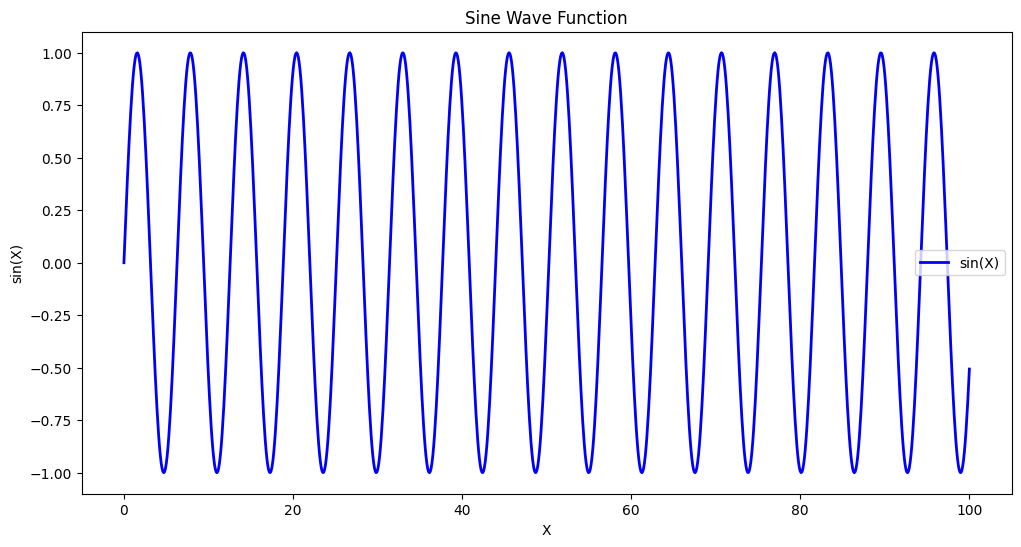

In [39]:
sequence, targets = generate_data()

## Step 4: Build the Recurrent Neural Network (RNN) Architecture

In [40]:
# Create the RNN model
class RNN(nn.Module):
  def __init__(self, input_size, hidden_size, output_size, num_layers=1):
     super(RNN, self).__init__()
     # input_size: input size
     # hidden_size: number of cells in the RNN hidden layer
     # num_layers: number of RNN layers
     self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True) # RNN layer
     # fully connected layer: output
     self.fc = nn.Linear(hidden_size, output_size)

  def forward(self, x):
      out, _ = self.rnn(x) # Feed input to RNN and get output
      out = self.fc(out[:, -1, :]) # Feed final output to the fully connected layer
      return out

## Step 5: Instantiate the Model & Set Hyperparameters

In [41]:
model = RNN(1, 16, 1, 1)

## Step 6: Train the RNN Model

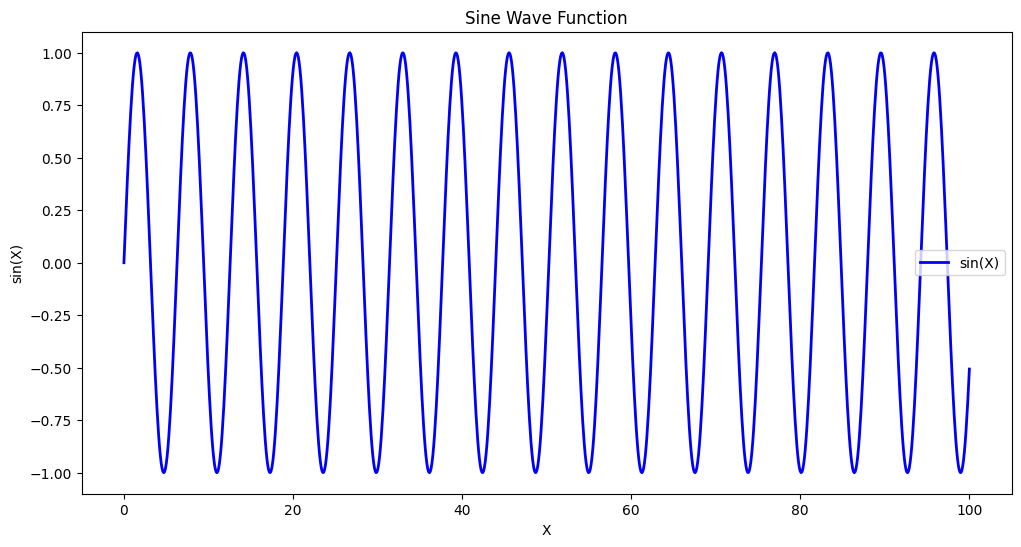

Epoch [1/20], Loss: 0.3884
Epoch [2/20], Loss: 0.1509
Epoch [3/20], Loss: 0.0368
Epoch [4/20], Loss: 0.0175
Epoch [5/20], Loss: 0.0077
Epoch [6/20], Loss: 0.0060
Epoch [7/20], Loss: 0.0046
Epoch [8/20], Loss: 0.0019
Epoch [9/20], Loss: 0.0021
Epoch [10/20], Loss: 0.0021
Epoch [11/20], Loss: 0.0015
Epoch [12/20], Loss: 0.0016
Epoch [13/20], Loss: 0.0012
Epoch [14/20], Loss: 0.0013
Epoch [15/20], Loss: 0.0012
Epoch [16/20], Loss: 0.0008
Epoch [17/20], Loss: 0.0006
Epoch [18/20], Loss: 0.0006
Epoch [19/20], Loss: 0.0012
Epoch [20/20], Loss: 0.0008


In [42]:
# RNN Training

# Hyperparameters
seq_length = 50 # Size of the input sequence
input_size = 1 # Dimension of the input sequence
hidden_size = 16 # Number of nodes in the RNN hidden layer
output_size = 1 # Output size or the predicted value
num_layers = 1 # Number of RNN layers
epochs = 20 # Number of times the model will be trained on the entire dataset
batch_size = 32 # Number of samples used in each training step
learning_rate = 0.001 # Learning rate or speed for the optimization algorithm

# Prepare data
X, y = generate_data(seq_length)
X = torch.tensor(X, dtype=torch.float32).unsqueeze(-1) # Convert numpy array to PyTorch tensor and add dimension
y = torch.tensor(y, dtype=torch.float32).unsqueeze(-1) # Convert numpy array to PyTorch tensor and add dimension

dataset = torch.utils.data.TensorDataset(X, y) # Create dataset
data_loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True) # Pass dataset to the loader

# Define the model
model = RNN(input_size, hidden_size, output_size, num_layers)
criterion = nn.MSELoss() # Loss function: Mean Squared Error
optimizer = optim.Adam(model.parameters(), lr=learning_rate) # Optimizer: Adam

# Train the model
for epoch in range(epochs):
    for batch_X, batch_y in data_loader:
        optimizer.zero_grad() # Reset gradients
        pred_y = model(batch_X) # Get model prediction
        loss = criterion(pred_y, batch_y) # Compare model prediction with actual values and calculate loss
        loss.backward() # Calculate gradients via backpropagation
        optimizer.step() # Update weights
    print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}')

## Step 7: Create Testing Sequences

In [43]:
# Create data for testing
X_test = np.linspace(100, 110, seq_length).reshape(1,-1) # First test data
y_test = np.sin(X_test) # Real value of test data

X_test2 = np.linspace(120, 130, seq_length).reshape(1,-1) # Second test data
y_test2 = np.sin(X_test2)

# Convert from numpy to tensor
X_test = torch.tensor(y_test, dtype=torch.float32).unsqueeze(-1)
X_test2 = torch.tensor(y_test2, dtype=torch.float32).unsqueeze(-1)

## Step 8: Perform Model Predictions

In [44]:
# Make predictions using the model
model = model.eval()
prediction1 = model(X_test).detach().numpy()
prediction2 = model(X_test2).detach().numpy()

## Step 9: Visualize Predicted Results

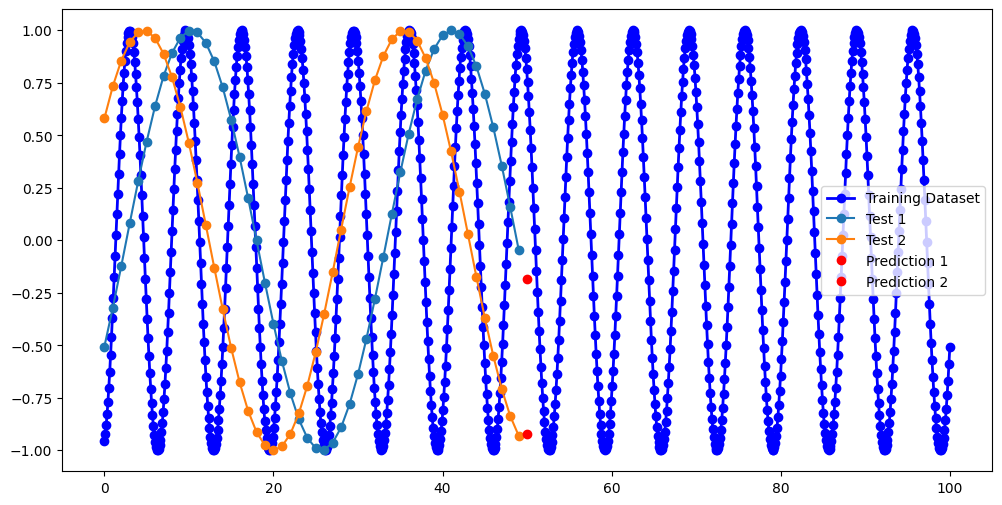

In [45]:
plt.figure(figsize=(12, 6))
plt.plot(np.linspace(0, 100, len(y)), y, marker = "o", label='Training Dataset', color='b', linewidth=2)
plt.plot(X_test.numpy().flatten(), marker="o", label="Test 1")
plt.plot(X_test2.numpy().flatten(), marker="o", label="Test 2")

plt.plot(np.arange(seq_length, seq_length + 1), prediction1.flatten(), "ro", label="Prediction 1")
plt.plot(np.arange(seq_length, seq_length + 1), prediction2.flatten(), "ro", label="Prediction 2")

plt.legend()
plt.show()